# 01. LaB6 instrument calibration with rietx

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sp8rks/Ceramic_Rietveld_Refinement/blob/main/scripted%20refinement%20%28rietx%29/01_LaB6_instrument_calibration.ipynb)


**Goal.** Measure the instrument (peak widths, peak shape, zero offset, axial divergence, Kα2 ratio) on a
line-position standard, so that later refinements can hold it fixed and attribute any extra broadening to
the specimen. This is step 1 of rietx's two-step lab workflow:

1. `plan="lab_calibrate"` on a standard with its certified cell **held fixed**, then `rx.save_instrument_profile`.
2. `plan="lab_sample_refine"` on a specimen after `rx.load_instrument_profile` (notebook 02).

**Data.** `refinement examples/LaB6/LaB6_Jan2018.raw` (Bruker RAW, Cu Kα, 10 to 70° 2θ) and the COD
structure `1000055.cif`. The GSAS-II refinement of the same scan in `refinement examples/LaB6/refinement/` is
used as a cross-check.

**What you will see.** A first attempt gives GoF 4.6, Durbin-Watson 0.17 and negative displacement
parameters, which GSAS-II also gives. We follow rietx's diagnostics to the physical cause (surface roughness
of the specimen), deal with two parameter pairs the data cannot separate, test which held cell the data
prefer, and compare the resulting calibration with GSAS-II's.

In [1]:
# Google Colab only: install rietx and fetch the workshop data. Running locally, this cell does nothing.
import os, subprocess, sys
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rietx[viz]==1.9.0"], check=True)
    if not os.path.isdir("/content/Ceramic_Rietveld_Refinement"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/sp8rks/Ceramic_Rietveld_Refinement.git",
                        "/content/Ceramic_Rietveld_Refinement"], check=True)
    os.chdir("/content/Ceramic_Rietveld_Refinement/scripted refinement (rietx)")
print("working directory:", os.path.basename(os.getcwd()))

working directory: scripted refinement (rietx)


In [2]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
import rietx as rx
from rietx.schemas.instrument import RoughnessPitschke, RoughnessSuortti
from gsas_lst import read_lst
%matplotlib inline

# show warnings in full, without the temporary file path of the cell that raised them
warnings.formatwarning = lambda msg, cat, *args, **kw: f"{cat.__name__}: {msg}\n"

DATA = Path("../refinement examples/LaB6")
PATTERN, CIF = DATA / "LaB6_Jan2018.raw", DATA / "1000055.cif"
LIMITS = (10.0, 70.0)          # the whole measured range
BISO_HELD = 0.3                # Å², a typical room-temperature value for both LaB6 sites

def show_diagnostics(result):
    """Print every diagnostic rietx attached to a fit, with its suggestion."""
    for d in result.diagnostics:
        print(f"[{d.level.upper()}] {d.code}  {', '.join(d.where)}")
        print("    ", d.message)
        if d.suggestion:
            print("     suggestion:", d.suggestion)

print("rietx", rx.__version__)

rietx 1.9.0


## 1. Read the pattern and its header

`rx.read_pattern` dispatches on the file's content. The header carries the anode, the Kα1 wavelength and
the goniometer radius. Note the **250 mm radius**: we come back to it in notebook 02, because the Al2O3/Si
scans were collected on a Bruker D2 Phaser, a much smaller (141 mm) instrument.

{'source_file': 'LaB6_Jan2018.raw', 'format': 'bruker_raw', 'scan': '0', 'scan_count': '1', 'scan_axis': 'locked coupled', 'anode': 'Cu', 'wavelength': '1.5406', 'goniometer_radius_mm': '250.0', 'count_time_s': '95.0'}
3040 points, step 0.0197 deg


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


...

findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['DejaVu Sans Mono'] not found. Falling back to DejaVu Sans.


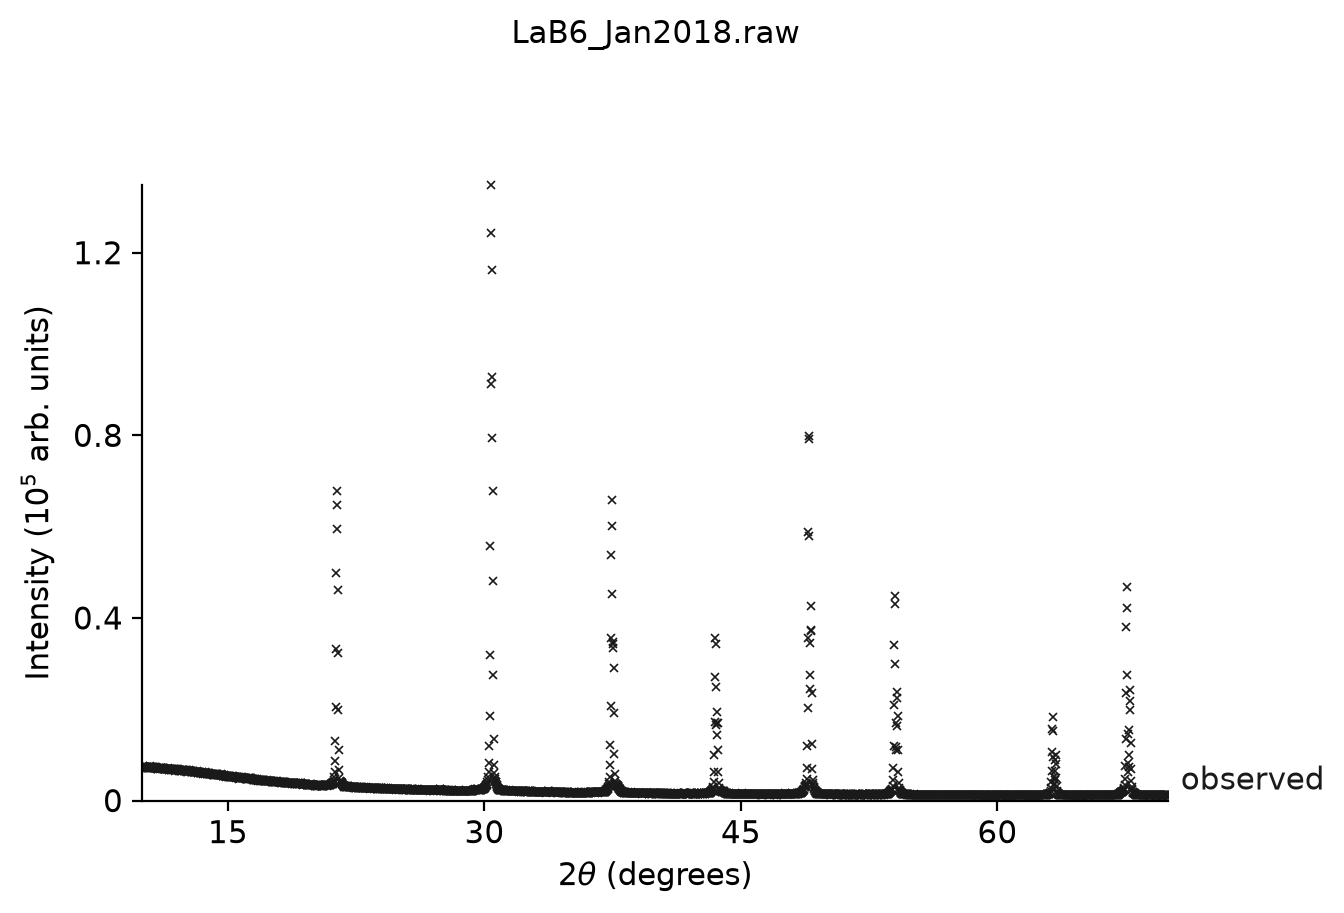

In [3]:
data = rx.read_pattern(PATTERN)
print(data.metadata)
print(len(data.two_theta), "points, step", round(float(np.diff(data.two_theta).mean()), 4), "deg")
data.plot(title="LaB6_Jan2018.raw", dpi=100)

## 2. The standard and the cell we hold

`lab_calibrate` holds the cell at a certified value, because only a known cell lets the fit tell a zero
offset from a lattice parameter.

**We do not know which NIST SRM lot (660a, 660b or 660c) this LaB6 is.** We therefore hold the cell at the
value in the CIF that ships with the data, COD 1000055, a = 4.157597 Å. That is not a certified value: the
660-series certificates all sit near 4.1569 Å (check the certificate for your lot), about 170 ppm smaller,
and the GSAS-II refinement in this repository held a = 4.15695 Å. Section 8 measures what this choice does
to the calibration.

In [4]:
def build_lab6(biso=BISO_HELD, roughness=None, two_theta_limits=LIMITS):
    structure = rx.Structure.from_cif(CIF)
    if biso is not None:                       # None keeps the CIF's own values
        for atom in structure.phases[0].atoms:
            atom.biso.value = biso
    instrument = rx.Instrument.bragg_brentano(radiation="CuKa", goniometer_radius_mm=250.0)
    instrument.background = rx.auto_background(data, kind="chebyshev", two_theta_limits=two_theta_limits)
    # Seed the widths from the strongest peaks (SKILL.md section 1): W ~ (0.6 H)^2, X ~ 0.6 H.
    strong = sorted(rx.pick_peaks(data, instrument).peaks, key=lambda p: -p.intensity)[:12]
    h = float(np.median([p.fwhm for p in strong]))
    instrument.profile.w.value, instrument.profile.x.value = (0.6 * h) ** 2, 0.6 * h
    if roughness is not None:
        instrument.geometry.surface_roughness = roughness
    return structure, instrument

structure, instrument = build_lab6()
ph = structure.phases[0]
print(ph.space_group, "a =", ph.cell.a.value, "Å held;", [(a.label, a.biso.value) for a in ph.atoms])

P m -3 m a = 4.157597 Å held; [('La', 0.3), ('B', 0.3)]


`auto_background` warns `BACKGROUND_ORDER_AT_CAP`: its Chebyshev order search hit 16 terms without the
residual between the peaks becoming white noise. The warning itself explains why: when every order leaves
correlated residual, the cause is **profile misfit leaking into the between-peak channels**, not too few
background terms. Keep that in mind; the misfit below is real.

## 3. First attempt: `lab_calibrate` with Biso free

This reproduces the quick first attempt: the plan's last stage frees Biso.

In [5]:
structure, instrument = build_lab6(biso=None)
ref_free = rx.Refinement(structure, instrument)
res_free = ref_free.fit(data, plan="lab_calibrate", two_theta_limits=LIMITS)
print(res_free)

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage zero_disp: converged (9 evals, ftol=1e-06)
  stage profile_w: converged (7 evals, ftol=1e-06)
  stage profile: converged (10 evals, ftol=1e-06)
  stage lines_axial: converged (68 evals, ftol=1e-06)
  stage biso: converged (48 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 7 unresolved
    WARNING BISO_NEGATIVE: phases.0.atoms.0.biso (B = -2.4 Å²) is below zero — no displacement does that: the Debye-Waller factor grows with sinθ/λ instead of falling, so the column is standing in for something else — a negative B usually absorbs an uncorrected absorption or surface-roughness effect, a wrong species or occupancy on that site, or a background that bends at high angle. Correct that, or hold B at a physical value and say so in the result
    WARNING BISO_NEGATIVE: phases.0.atoms.1.biso (B = -2.05 Å²) is below zero — no displacement does that: the Debye-Waller factor grows with sin

What each diagnostic means here:

* **`BISO_NEGATIVE`** on both sites (about −2.4 and −2.0 Å²). No thermal motion does that. A negative B says
  the calculated intensities fall off with angle faster than the observed ones, and the B column is standing
  in for something else. The message lists the usual suspects: surface roughness, absorption, a wrong
  occupancy, a background that bends at high angle.
* **`HIGH_CORRELATION` / `FLAT_DIRECTION`, axial S/L and H/L (ρ = −1.000).** The two Finger-Cox-Jephcoat
  terms are not separable on this pattern; only their combination is measured.
* **`HIGH_CORRELATION`, zero shift and sample displacement (ρ = +0.999).** Holding the cell is supposed to
  separate them, but over 10 to 70° the displacement shift (∝ cos θ) is almost a constant. One of the two
  has to be fixed by something outside this fit.
* **`DATA_SUPPORT_LOW`** (info): 9 reflections for the structural parameters freed. Expected for a cubic
  standard on a short range.
* **`PATTERN_UNDERSAMPLED`**: 4.3 steps across the FWHM against the 5 the guidelines ask for. This is a data
  collection limit (0.02° steps on 0.075° peaks). Peak-shape parameters will carry some error that nothing
  after the fact can remove.

GSAS-II, refining the same scan, lands in the same place:

In [6]:
gsas = read_lst(DATA / "refinement" / "test.lst")
u = gsas["phases"]["B6 La"]["uiso"]
print(f"GSAS-II: wR = {gsas['wR']:.4f}, GOF = {gsas['gof']}, Durbin-Watson = {gsas['durbin_watson']}")
print("GSAS-II Uiso (Å²):", u, "-> Biso = 8π²U:", {k: round(8 * np.pi**2 * v, 2) for k, v in u.items()})
s = res_free.statistics
print(f"rietx:   Rwp = {s.rwp:.4f}, GoF = {s.gof:.2f}, Durbin-Watson = {s.durbin_watson:.2f}")

GSAS-II: wR = 0.0962, GOF = 5.36, Durbin-Watson = 0.172
GSAS-II Uiso (Å²): {'La': -0.01884, 'B': -0.01132} -> Biso = 8π²U: {'La': -1.49, 'B': -0.89}
rietx:   Rwp = 0.0775, GoF = 4.58, Durbin-Watson = 0.17


Two independent codes agree on the symptom. GSAS-II's displacement parameters are just as negative
(Biso ≈ −1.5 and −0.9 Å²), and its Durbin-Watson statistic is 0.17 as well. The fault is in the model of the
experiment, not in either program.

## 4. Hold Biso at a physical value and read what is left

Holding Biso at 0.3 Å² removes the impossible values. It does **not** fix the fit, which is the important
part: GoF gets worse, because the angle-dependent intensity error that B was absorbing now has nowhere to go.

In [7]:
structure, instrument = build_lab6()
ref_held = rx.Refinement(structure, instrument)
ref_held.hold(["phases.*.atoms.*.biso"])        # a plan replaces vary flags, so hold() is the way to pin
res_held = ref_held.fit(data, plan="lab_calibrate", two_theta_limits=LIMITS)
print(res_held)

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage zero_disp: converged (9 evals, ftol=1e-06)
  stage profile_w: converged (7 evals, ftol=1e-06)
  stage profile: converged (10 evals, ftol=1e-06)
  stage lines_axial: converged (61 evals, ftol=1e-06)
  stage biso: converged (57 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 6 unresolved
    WARNING FLOOR_HIT: instrument.profile.y refined to its floor (ρ=+0.047) — the data push this parameter below zero, where it cannot go. The usual reasons are a phase or term the data do not support, a width the instrument already supplies, or, for a displacement parameter, absorption or a wrong species or occupancy. Fix it at 0
    WARNING HIGH_CORRELATION: instrument.geometry.axial_sl ~ instrument.geometry.axial_hl (ρ=-1.000) — flagged in stages: lines_axial, biso — consider fixing one of the correlated parameters
    WARNING FLAT_DIRECTION: instrument.geometry.axial_sl ~ instrument.geometr

`HOLD_BLOCKED_PLAN` (info) is the hold doing its job: the `biso` stage wanted to free those parameters and the
hold won. `FLOOR_HIT` on the Lorentzian `Y` term says the data ask for less Lorentzian strain-like width than
zero; it is held at its floor.

Now ask rietx's report where the misfit lives. Layer 1 decomposes each misfitting region into position,
width, mixing, asymmetry and **intensity** errors. The intensity coefficient is the relative error of the
calculated intensity in that region.

In [8]:
rep_held = ref_held.report(plan="lab_calibrate")
rows = []
for a in rep_held.attribution:
    coeff = {c.kind: c for c in a.coefficients}
    rows.append((a.mean_two_theta, coeff["intensity"].value, coeff["intensity"].stderr, a.chi2_share))
rows.sort()
print(" 2θ (deg)   intensity error   χ² share")
for tt, v, e, share in rows:
    print(f"{tt:8.2f}    {v:+.3f} ± {e:.3f}      {share:.3f}")

 2θ (deg)   intensity error   χ² share
   21.39    -0.325 ± 0.004      0.430
   30.42    -0.065 ± 0.005      0.027
   37.49    +0.150 ± 0.012      0.048
   43.56    +0.224 ± 0.009      0.043
   49.01    +0.279 ± 0.007      0.152
   54.05    +0.317 ± 0.008      0.099
   63.29    +0.396 ± 0.009      0.047
   67.62    +0.323 ± 0.009      0.106


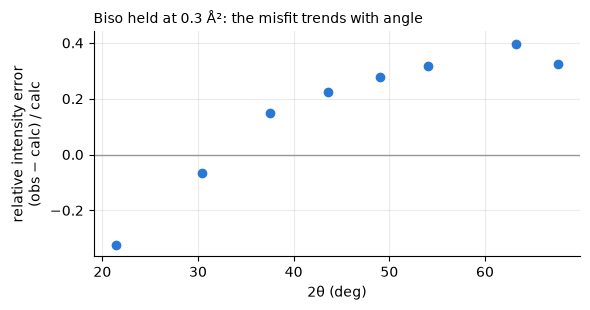

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.2))
tt, v, e, _ = map(np.array, zip(*rows))
ax.errorbar(tt, v, yerr=e, fmt="o", ms=6, color="#2a78d6", ecolor="#2a78d6", lw=2, capsize=0)
ax.axhline(0, color="0.6", lw=1)
ax.set_xlabel("2θ (deg)")
ax.set_ylabel("relative intensity error\n(obs − calc) / calc")
ax.set_title("Biso held at 0.3 Å²: the misfit trends with angle", fontsize=10, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25)
plt.tight_layout()

The pattern is unambiguous. The (100) line at 21.4° is calculated about 30 % **too strong**, and every line
above 45° is calculated 25 to 40 % **too weak**. Observed intensity is depressed at low angle relative to high
angle. That is exactly what a free, negative B reproduces, and it is also the textbook signature of
**surface roughness**: on a rough or loosely packed flat specimen the beam crosses a porous top layer at
grazing incidence, so low-angle reflections lose intensity (Suortti 1972; Pitschke et al. 1993).

## 5. Rival explanations, tested

Three physical causes can depress low-angle intensity on a Bragg-Brentano instrument. We test each against
the same data, with Biso held at 0.3 Å².

* **Surface roughness** (Suortti or Pitschke form). rietx models both.
* **A variable (automatic) divergence slit**, which makes intensity grow as sin θ. rietx has no slit model, so
  we convert the counts to fixed-slit equivalent (divide by sin θ, propagating σ) and refit with no extra
  parameter. The header stores a fixed 0.6 slit value, so we expect this to fail.
* **A thin specimen**, which goes the wrong way: a layer thinner than the beam's penetration loses intensity
  at *high* angle, not low. LaB6 absorbs so strongly (µ ≈ 1100 cm⁻¹) that the specimen is effectively
  infinitely thick anyway, so we do not fit it.

In [10]:
def calibrate(roughness=None, pattern=None, label=""):
    """lab_calibrate with Biso held; then, if a roughness model is declared, one stage that frees it."""
    pattern = data if pattern is None else pattern
    structure, instrument = build_lab6(roughness=roughness)
    ref = rx.Refinement(structure, instrument)
    ref.hold(["phases.*.atoms.*.biso"])
    res = ref.fit(pattern, plan="lab_calibrate", two_theta_limits=LIMITS)
    if roughness is not None:
        res = ref.run_stage(pattern, rx.Stage(name="roughness",
                            turn_on=["instrument.geometry.surface_roughness.*"]), two_theta_limits=LIMITS)
    rep = ref.report(plan="lab_calibrate")
    s = res.statistics
    print(f"{label:34s} GoF {s.gof:5.2f}  DW {s.durbin_watson:4.2f}  "
          f"Le Bail gap {rep.lebail_gap.ratio:4.2f}  codes {sorted({d.code for d in res.diagnostics})}")
    return ref, res

# Variable-slit hypothesis: fixed-slit equivalent counts, σ propagated (not recomputed from the new counts).
tt = np.asarray(data.two_theta); y = np.asarray(data.intensity); sin_t = np.sin(np.radians(tt / 2))
k = sin_t.mean()
vds = rx.PatternData(two_theta=tt.tolist(), intensity=(y / sin_t * k).tolist(),
                     sigma=(np.sqrt(np.maximum(y, 1)) / sin_t * k).tolist(), metadata=data.metadata)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")            # BACKGROUND_ORDER_AT_CAP, already discussed above
    _ = calibrate(label="no correction")
    _ = calibrate(pattern=vds, label="variable slit (data converted)")
    _ = calibrate(RoughnessSuortti(), label="roughness, Suortti")
    ref_p, res_p = calibrate(RoughnessPitschke(), label="roughness, Pitschke")

no correction                      GoF  7.77  DW 0.08  Le Bail gap 3.14  codes ['FLAT_DIRECTION', 'FLOOR_HIT', 'HIGH_CORRELATION', 'HOLD_BLOCKED_PLAN', 'PATTERN_UNDERSAMPLED']


variable slit (data converted)     GoF  4.65  DW 0.17  Le Bail gap 1.79  codes ['FLAT_DIRECTION', 'FLOOR_HIT', 'HIGH_CORRELATION', 'HOLD_BLOCKED_PLAN', 'PATTERN_UNDERSAMPLED']


roughness, Suortti                 GoF  2.31  DW 0.59  Le Bail gap 1.07  codes ['FLAT_DIRECTION', 'FLOOR_HIT', 'HIGH_CORRELATION', 'PATTERN_UNDERSAMPLED']


roughness, Pitschke                GoF  2.28  DW 0.61  Le Bail gap 1.05  codes ['FLAT_DIRECTION', 'HIGH_CORRELATION', 'PATTERN_UNDERSAMPLED']


How to read this table:

* **GoF** falls from 7.8 to 2.3 with either roughness model. The variable-slit conversion helps much less
  (4.7) and adds no parameter, so it is not the cause, consistent with the fixed slit in the header.
* The **Le Bail gap** is Rietveld Rwp over a Le Bail (free-intensity) Rwp at the same profile. At 3.1 it said
  the *intensity model* carried the misfit while positions and widths were fine. With roughness it drops to
  about 1.05: the structural intensities now account for the pattern.
* The Suortti fit reports `FLOOR_HIT` on its `a` parameter, the fraction of intensity that survives at grazing
  incidence, which went to zero. The Pitschke form fits as well without reaching a bound, so we carry it.

Is roughness worth its two parameters? Biso has no "null" value, so rietx's swap test
(`rx.report.compare_rivals`) refuses this pair and says it is settled by protocol: here, holding B at a physical
value. What we can price is the roughness itself, with `compare_freed` (ΔBIC at the effective number of
observations, N/f², with f the esd inflation):

In [11]:
try:
    rx.report.compare_rivals(ref_p, data, ("phases.0.atoms.0.biso", "instrument.geometry.surface_roughness.c"))
except ValueError as exc:
    print("compare_rivals:", str(exc)[:240], "...")

compare_rivals: 'phases.0.atoms.0.biso' has no null identity, so it has no 'held at its null' fit: this pair is resolved by protocol (fix the zero on a calibrant, widen the window, measure a standard), not by a swap; nulls are defined for ['instrument.geom ...


In [12]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    structure, instrument = build_lab6(roughness=RoughnessPitschke())
base = rx.Refinement(structure, instrument)
base.hold(["phases.*.atoms.*.biso", "instrument.geometry.sample_displacement"])
base.tie_equal(["instrument.geometry.axial_sl", "instrument.geometry.axial_hl"])
res_base = base.fit(data, plan="lab_calibrate", two_theta_limits=LIMITS)

final = base.branch()                          # same history; the branch adds one stage
res_final = final.run_stage(data, rx.Stage(name="roughness",
                            turn_on=["instrument.geometry.surface_roughness.*"]), two_theta_limits=LIMITS)
freed = rx.report.compare_freed(base, final)
for p in freed.freed:
    print(f"{p.path:45s} {p.value:8.4f} ± {p.esd:.4f}   t = {p.t_ratio:+.1f} (vs held value {p.held_at})")
print(f"ΔBIC at N/f² = {freed.delta_bic:.0f}   (N = {freed.n_points}, N_eff = {freed.n_effective:.0f})")

instrument.geometry.surface_roughness.c         3.5971 ± 0.3699   t = +9.7 (vs held value 0.0)
instrument.geometry.surface_roughness.tau       0.0441 ± 0.0071   t = -0.8 (vs held value 0.05)
ΔBIC at N/f² = 327   (N = 3039, N_eff = 154)


ΔBIC of about +330 at the effective N is decisive: roughness pays for itself many times over. The strength
coefficient `c` is about 10 standard errors from zero. (`tau` is measured against its default starting value,
0.05, not against zero, so its t-ratio is not a test of anything.)

The cell above already contains the two choices for the parameter pairs the first fit could not separate:

* **Axial divergence: `tie_equal(axial_sl, axial_hl)`.** One number for S/L = H/L is what the data can
  measure. GSAS-II makes the same choice with its single `SH/L` term (it models the sum).
* **Zero vs displacement: hold the displacement at 0.** With ρ = 0.997 even with the cell held, one of them
  has to carry the whole position offset. We let the zero carry it and hold the displacement, because
  displacement is a property of each mounted specimen and is refined again for every sample in
  `lab_sample_refine`. The price: this zero includes whatever height error this LaB6 mount had.

## 6. The calibrated fit

In [13]:
print(res_final)

RefinementResult: converged (rietveld)
  stage roughness: converged (18 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 2 unresolved
    WARNING HIGH_CORRELATION: instrument.geometry.surface_roughness.c ~ instrument.geometry.surface_roughness.tau (ρ=-0.996) — consider fixing one of the correlated parameters
    WARNING PATTERN_UNDERSAMPLED: 4.3 steps across the FWHM (median over 13 fitted peaks) — below the 5 the guidelines ask for — a data-collection limit, not a refinement one: the integrated intensities were not measured finely enough and no choice made here recovers them. Re-collect at a step size near FWHM/5 if the intensities have to be quotable
  provenance: rietx 1.9.0, backend=numpy, solver=lm
  Rwp 0.0445 / Rexp 0.0169 (GoF 2.62), Rp 0.0302, χ² 6.9, DW 0.56


Remaining diagnostics:

* **`HIGH_CORRELATION` between the two Pitschke parameters (ρ = −0.996).** Only their combination (how much
  low-angle intensity is lost) is measured. Neither number is quoted alone and neither is saved: roughness is a
  property of this specimen, not of the instrument.
* **`PATTERN_UNDERSAMPLED`** remains, as it must.

In [14]:
rep_final = final.report(plan="lab_calibrate")
print(rep_final.summary)
print()
for a in rep_final.suggested_actions:
    print(f"suggested: {a.kind} (confidence {a.confidence:.2f}): {a.rationale[:160]}...")

Rwp=0.0445 GoF=2.62; 11 regions, top 11 shown (78% of χ²); 16 unmatched observed peak(s); fitted instrument.zero_shift = 0.0241863 stands 69σ from 0 but is exchangeable with the held instrument.geometry.sample_transparency (R² = 0.9548) (and 1 more held candidate(s), see identifiability.exchanges) — this fit cannot tell which is physical; resolve it by measurement, never by freeing both into one fit (that is a ridge): fit each of the pair alone with the other held at its null and compare χ²; a χ² gap of ≥ 10% means the data has chosen — the winning rival's fit is the answer, quoted without caveat; a smaller gap means the pair is genuinely unresolved: fix it by protocol (a calibrant-fixed zero, a wider window) or say the data has not chosen; the combination 0.76·instrument.geometry.surface_roughness.tau −0.63·instrument.geometry.surface_roughness.c +0.14·phases.0.scale is unconstrained at the 7.0e-04 level — these parameters trade freely and their individual esds are not independent; La

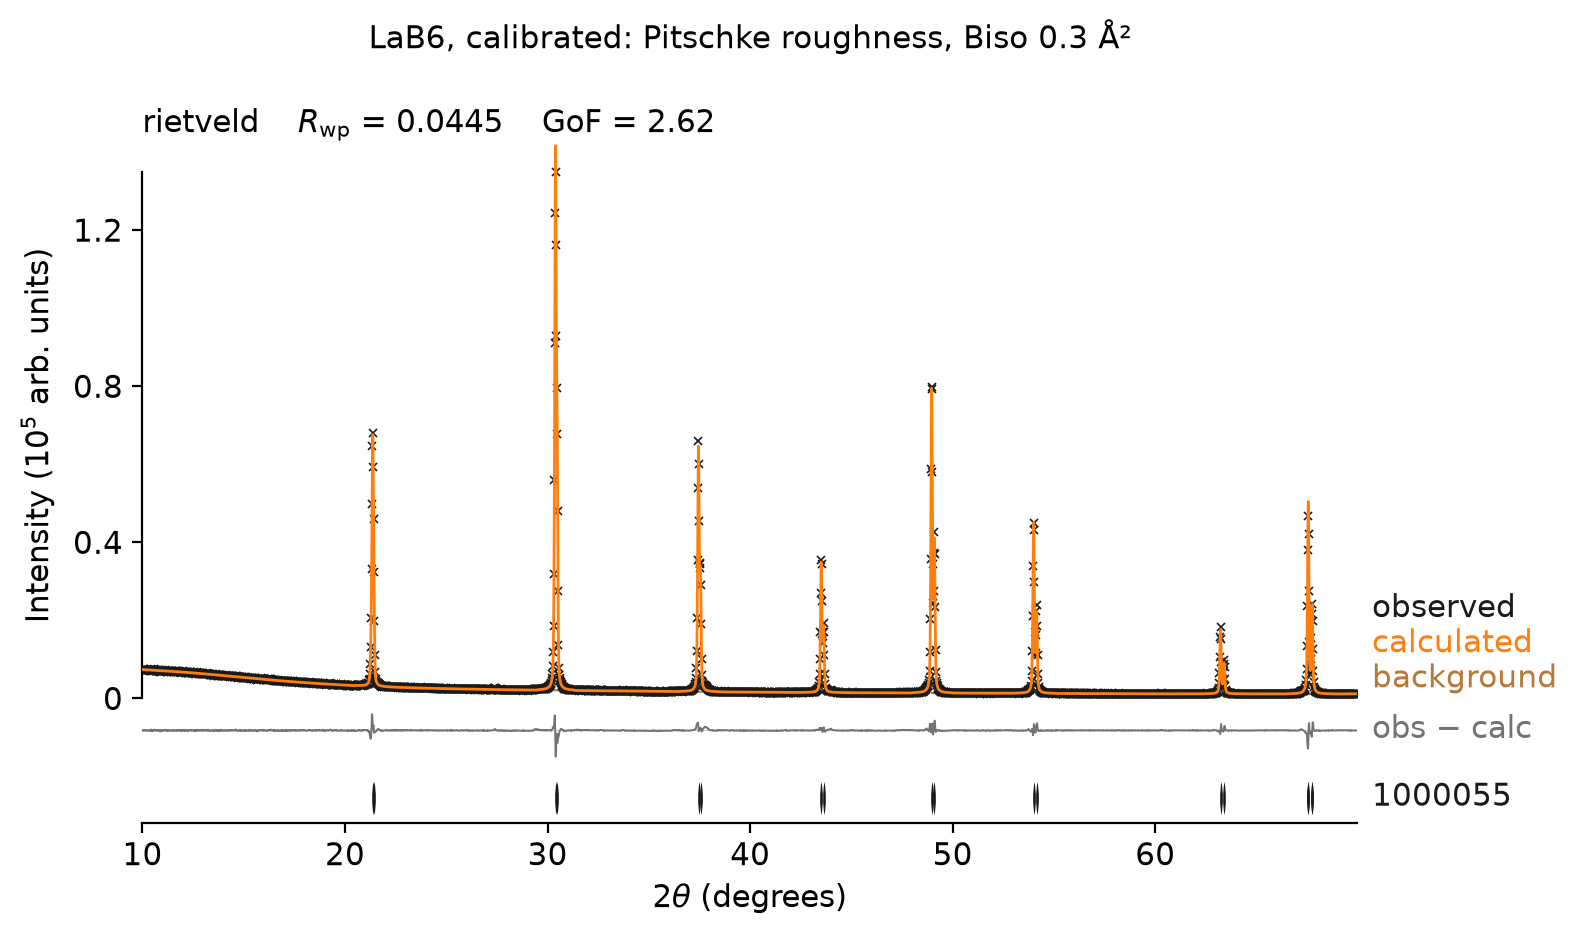

In [15]:
rx.viz.plot_result(res_final, figsize=(9, 4.5), dpi=110, title="LaB6, calibrated: Pitschke roughness, Biso 0.3 Å²")

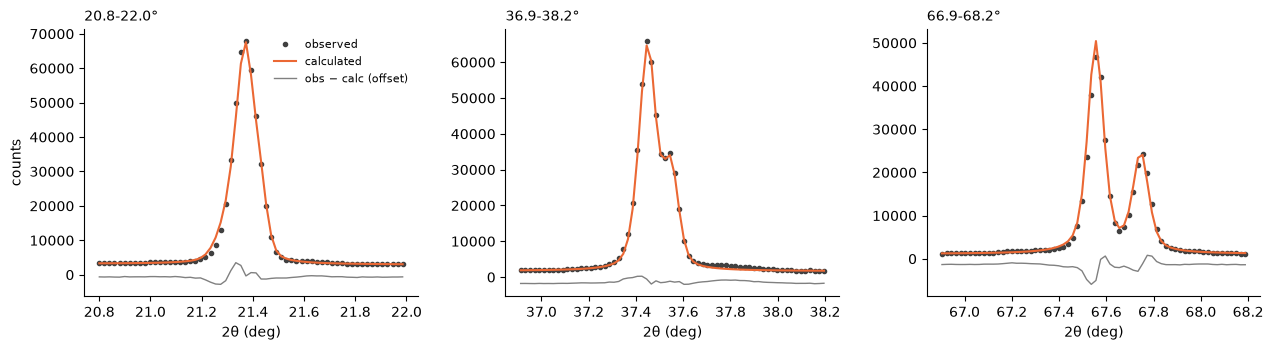

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (lo, hi) in zip(axes, [(20.8, 22.0), (36.9, 38.2), (66.9, 68.2)]):
    m = (np.asarray(res_final.two_theta) > lo) & (np.asarray(res_final.two_theta) < hi)
    x = np.asarray(res_final.two_theta)[m]
    obs, calc = np.asarray(res_final.y_obs)[m], np.asarray(res_final.y_calc)[m]
    ax.plot(x, obs, "o", ms=3, color="0.25", label="observed")
    ax.plot(x, calc, color="#eb6834", lw=1.5, label="calculated")
    ax.plot(x, obs - calc + 0.9 * obs.min() - 0.05 * obs.max(), color="0.5", lw=1, label="obs − calc (offset)")
    ax.set_title(f"{lo}-{hi}°", fontsize=10, loc="left"); ax.set_xlabel("2θ (deg)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("counts"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

Reading the plot: the strong lines are now well fitted. What remains is (left) a small low-angle asymmetry on
(100), the region behind the `refine_axial_asymmetry` suggestion, and (right) a peak-shape residual at the
top and sides of the high-angle Kα1/Kα2 pairs, where only about four points cover each FWHM.

### The "unmatched peaks" are not an impurity

The report lists unmatched observed peaks and suggests `add_impurity_phase`. Before believing it, compare each
one with where LaB6 puts its lines, both the Kα1 lines and their **Cu Kβ** copies (λ from rietx's own NIST
table, not typed in).

In [17]:
from rietx.crystallography.dispersion import edges
kbeta = next(a["kbeta"] for a in rx.capabilities().model_dump()["anodes"] if a["name"] == "CuKa")
a0 = 4.157597
hkls = [(1,0,0),(1,1,0),(1,1,1),(2,0,0),(2,1,0),(2,1,1),(2,2,0),(2,2,1),(3,1,0)]
d = {h: a0 / np.sqrt(sum(i * i for i in h)) for h in hkls}
lines = {f"{h} Kα1": 2 * np.degrees(np.arcsin(1.5405929 / (2 * dd))) for h, dd in d.items()}
lines.update({f"{h} Kβ": 2 * np.degrees(np.arcsin(kbeta / (2 * dd))) for h, dd in d.items()})
print(f"Cu Kβ = {kbeta} Å")
print(" unmatched 2θ   height/σ   nearest LaB6 line          Δ (deg)")
for u in sorted((u for u in rep_final.unmatched if u.kind == "unmatched_obs"), key=lambda u: u.two_theta):
    name, pos = min(lines.items(), key=lambda kv: abs(kv[1] - u.two_theta))
    print(f"   {u.two_theta:7.2f}    {u.height_over_sigma:6.1f}     {name:22s} {u.two_theta - pos:+.2f}")

# Where the Ni filter's K edge cuts the white radiation diffracted by the strongest line, (110).
lam_edge = 12398.42 / edges("Ni")[0]          # rietx locates the edge to about 0.4 %
print()
print(f"Ni K edge ≈ {lam_edge:.3f} Å -> (110) white-radiation cut-off at 2θ ≈ "
      f"{2 * np.degrees(np.arcsin(lam_edge / (2 * d[(1,1,0)]))):.2f}°")

Cu Kβ = 1.392234 Å
 unmatched 2θ   height/σ   nearest LaB6 line          Δ (deg)
     21.63       6.0     (1, 0, 0) Kα1          +0.28
     27.41       7.0     (1, 1, 0) Kβ           +0.02
     29.43       6.9     (1, 1, 0) Kα1          -0.95
     29.55       5.3     (1, 1, 0) Kα1          -0.83
     30.67       7.0     (1, 1, 0) Kα1          +0.29
     31.46       5.1     (1, 1, 0) Kα1          +1.08
     37.35      14.0     (1, 1, 1) Kα1          -0.09
     37.82      16.7     (1, 1, 1) Kα1          +0.39
     37.92      10.2     (1, 1, 1) Kα1          +0.48
     43.43       8.8     (2, 0, 0) Kα1          -0.07
     43.90       5.2     (2, 1, 0) Kβ           -0.07
     44.00      10.2     (2, 1, 0) Kβ           +0.03
     48.72       9.6     (2, 1, 0) Kα1          -0.23
     48.88      15.6     (2, 1, 0) Kα1          -0.07
     53.73       7.2     (2, 1, 1) Kα1          -0.24
     67.20       7.8     (2, 2, 1) Kα1          -0.33

Ni K edge ≈ 1.485 Å -> (110) white-radiation cut-off a

Three kinds of match:

* **Kβ leakage.** 27.41° and 44.0° sit within 0.03° of the Cu Kβ copies of (110) and (210): the Ni filter lets a
  little Kβ through. That is normal for a filtered tube and does not belong in an instrument profile that will be
  reused on other specimens.
* **The white-radiation foot of the strongest line.** 29.4 to 31.5° lies within about 1° of (110), the
  strongest line by far. Bremsstrahlung diffracted by (110) at wavelengths longer than the Ni K edge passes the
  filter, which puts a low, broad foot on that line starting near 29.3°, where the edge cuts it off. A
  characteristic-line model has nothing for it.
* **Tails of strong LaB6 lines.** The rest sit 0.1 to 0.5° from a strong Kα1 line, on the flanks the zoomed
  plots show: residual peak-shape misfit on undersampled peaks.

So the honest reading is: no impurity phase, a small Kβ leak, white radiation under the strongest line, and a
peak-shape limit set by the step size.

## 7. Which held cell? And a side-by-side with GSAS-II

GSAS-II held a = 4.15695 Å, close to the 660-series certificates, where we held the CIF's 4.157597 Å. A fair
comparison holds the same cell, so we calibrate at both. GSAS-II's `SH/L` is one combined number, (S + H)/L,
so it compares with the **sum** of rietx's two equal axial terms.

In [18]:
def calibrated(a_cell):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        structure, instrument = build_lab6(roughness=RoughnessPitschke())
    structure.phases[0].cell.a.value = a_cell
    r = rx.Refinement(structure, instrument)
    r.hold(["phases.*.atoms.*.biso", "instrument.geometry.sample_displacement"])
    r.tie_equal(["instrument.geometry.axial_sl", "instrument.geometry.axial_hl"])
    r.fit(data, plan="lab_calibrate", two_theta_limits=LIMITS)
    return r.run_stage(data, rx.Stage(name="roughness", turn_on=["instrument.geometry.surface_roughness.*"]),
                       two_theta_limits=LIMITS)

runs = {"rietx, CIF cell": (4.157597, res_final), "rietx, GSAS-II cell": (4.15695, calibrated(4.15695))}
print(f"{'':24s}{'held a (Å)':>11s}{'zero (deg)':>18s}{'S/L + H/L':>18s}{'W (deg²)':>10s}{'GoF':>7s}{'DW':>7s}")
for name, (a_cell, r) in runs.items():
    v = {p.path: p for p in r.parameters}
    z, sl, w = v["instrument.zero_shift"], v["instrument.geometry.axial_sl"], v["instrument.profile.w"]
    print(f"{name:24s}{a_cell:11.6f}{z.value:11.4f} ± {z.stderr:.4f}{2*sl.value:11.4f} ± {2*sl.stderr:.4f}"
          f"{w.value:10.5f}{r.statistics.gof:7.2f}{r.statistics.durbin_watson:7.2f}")
print(f"{'GSAS-II (test.lst)':24s}{4.15695:11.5f}{0.022947:11.4f} ± 0.0003{0.046315:11.4f} ± 0.0004"
      f"{'':>10s}{gsas['gof']:7.2f}{gsas['durbin_watson']:7.3f}")
print("GSAS-II Biso (Å²) La, B:", {k: round(8 * np.pi**2 * v, 2) for k, v in gsas["phases"]["B6 La"]["uiso"].items()}, "; rietx: 0.3 held, roughness refined")

                         held a (Å)        zero (deg)         S/L + H/L  W (deg²)    GoF     DW
rietx, CIF cell            4.157597     0.0242 ± 0.0004     0.0467 ± 0.0006   0.00120   2.62   0.56
rietx, GSAS-II cell        4.156950     0.0147 ± 0.0003     0.0421 ± 0.0006   0.00182   2.30   0.60
GSAS-II (test.lst)          4.15695     0.0229 ± 0.0003     0.0463 ± 0.0004             5.36  0.172
GSAS-II Biso (Å²) La, B: {'La': -1.49, 'B': -0.89} ; rietx: 0.3 held, roughness refined


What this says:

* **The data prefer the certificate-like cell.** Holding 4.15695 Å instead of the CIF value lowers χ² by about
  30 % (GoF 2.62 → 2.30). A cell error is not exactly a zero error (one shifts lines as tan θ, the other by a
  constant), so a wrong held cell leaves a position residual that the widths and shape terms then absorb. That
  is evidence, though not proof, that this specimen is a 660-series standard and that the CIF value is the
  wrong reference for it.
* **The zero shift depends on the held cell**: 0.024° with the CIF cell, 0.015° with the GSAS-II cell. Any
  absolute lattice parameter measured later with this calibration inherits that choice.
* **Against GSAS-II at the same held cell**, the zero differs by about 0.008° and the axial divergence by about
  9 %. With the CIF cell, rietx happens to land within 0.002° and 1 % of GSAS-II's numbers, so that closer
  match is partly coincidence: zero, axial divergence and the held cell trade against each other, and the two
  codes model the specimen differently (roughness against negative B) on peaks that are undersampled. Read
  instrument constants from two codes as agreeing to roughly this level, not to their esds. The fit quality
  differs where the models differ: GoF 2.3 against 5.4, Durbin-Watson 0.6 against 0.17.

**What we save.** As planned, the saved profile uses the CIF cell, because the lot is unknown. If you can
confirm the lot, refit with its certified cell; the evidence above suggests that will give a better
calibration.

## 8. Save the instrument profile

`rx.save_instrument_profile` writes the calibrated **instrument** only: wavelengths and the refined Kα2 ratio,
widths, axial divergence, zero shift, and the geometry. The specimen-side terms (roughness, displacement,
background, structure) are not instrument properties and are not saved.

In [19]:
calibrated_instrument = final.fitted_instrument
rx.save_instrument_profile(calibrated_instrument, "lab_profile.json")
reloaded = rx.load_instrument_profile("lab_profile.json")
g, p = reloaded.geometry, reloaded.profile
print("goniometer radius:", g.goniometer_radius_mm, "mm   roughness saved:", g.surface_roughness)
print("U V W X Y:", [round(getattr(p, k).value, 5) for k in "uvwxy"])
print("axial S/L = H/L:", round(g.axial_sl.value, 4), "  zero:", round(reloaded.zero_shift.value, 4),
      "  Kα2/Kα1:", round(reloaded.source.lines[1].weight.value, 3))

goniometer radius: 250.0 mm   roughness saved: None
U V W X Y: [-0.01177, 0.01005, 0.0012, 0.01605, 0.03579]
axial S/L = H/L: 0.0234   zero: 0.0242   Kα2/Kα1: 0.467


## Summary

| Step | What rietx said | What we did |
|---|---|---|
| First fit, Biso free | `BISO_NEGATIVE`, GoF 4.6, DW 0.17 (GSAS-II: same) | looked for what B was absorbing |
| Biso held at 0.3 Å² | GoF 7.8; Layer 1: intensity too strong at low angle, too weak at high | tested three causes |
| Rival causes | roughness GoF 2.3, variable slit 4.7; Le Bail gap 3.1 → 1.05 | adopted Pitschke roughness (ΔBIC ≈ +330) |
| S/L vs H/L | `FLAT_DIRECTION`, ρ = −1 | `tie_equal`, as GSAS-II does |
| zero vs displacement | ρ = 0.999 even with the cell held | held displacement, zero carries the offset |
| Unmatched peaks | `add_impurity_phase` | Kβ leakage, white radiation, peak tails: no impurity |
| Held cell | CIF value vs 4.15695 Å: GoF 2.62 vs 2.30 | saved with the CIF cell (lot unknown), flagged |

**Caveats to carry forward.**

1. The held cell is the CIF value, not a certified one. The data prefer 4.15695 Å (χ² about 30 % lower), and
   the zero shift moves by 0.009° between the two choices.
2. The scan is undersampled (4.3 steps per FWHM), which limits the peak-shape calibration.
3. This profile belongs to the instrument that measured this LaB6 (250 mm radius, RAW v1 file from 2018).
   It is only valid for data from the same instrument and optics. Notebook 02 checks whether that holds for
   the Al2O3/Si scans.

**Provenance.**

In [20]:
print(res_final.provenance)

Provenance
  package_version: '1.9.0'
  schema_version: '0.55'
  backend: 'numpy'
  dtype: 'float64'
  solver: 'lm'
  report_thresholds_version: '1.12'
  created_utc: '2026-10-23T22:00:52Z'
